# Week 6: Decision Trees and Random Forests
**Rupal Paliwal, Mod C, Semester 1**

**Dataset:** Movies Box Office 2000 to 2024 (Kaggle), the same 5,000 films used in earlier weeks.

**Questions:**
1. **Classification:** is a film a hit (worldwide gross above the median)? Can trees beat logistic regression (78.3%) and the SVM (78.4%)?
2. **Regression:** how well can a random forest predict log worldwide revenue, compared with the linear model (R² 0.526) and the polynomial model (R² 0.617)?
3. Which features matter most, and how much can we predict **before** release, without vote count or rating?

**Part 1** uses the box office data. **Part 2** adds the other two project datasets, MovieLens 20M and the 4 Services Streaming catalogs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, r2_score

## 1. Load and prepare the data

Same preparation as Weeks 2 and 4: rating converted from text like `'8.217/10'`, vote count logged, genres as 0/1 columns, the top 10 languages as 0/1 columns (English is the reference), and rows with missing or zero ratings dropped. The money columns other than the target are left out because worldwide gross is domestic plus foreign, so they would leak the answer.

Trees split on one feature at a time, so they **don't need feature scaling**.

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')

data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

# Numeric features
X = pd.DataFrame({
    'log_votes': np.log1p(data['Vote_Count']),
    'rating': data['Rating_num'],
    'year': data['Year'],
}, index=data.index)

# Genres (multi hot) and top 10 languages (English is the reference)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)

X = pd.concat([X, genres, langs], axis=1)
threshold = df['$Worldwide'].median()
y_hit = (data['$Worldwide'] > threshold).astype(int)
y_rev = np.log(data['$Worldwide'])

# Same splits as earlier weeks, so results are comparable
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_hit, test_size=0.2, random_state=42, stratify=y_hit)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y_rev, test_size=0.2, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
print('Rows:', len(X), '| Features:', X.shape[1])

Rows: 4803 | Features: 32


## 2. A single decision tree: watching it overfit

I grow classification trees of increasing depth (splits chosen by **entropy / information gain**, as in the lesson) and compare training accuracy with 5 fold CV accuracy. CV accuracy is measured on films the tree didn't train on.

In [3]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, criterion='entropy', random_state=42)
    cv = cross_val_score(tree, Xc_train, yc_train, cv=skf).mean()
    tree.fit(Xc_train, yc_train)
    rows.append({'max_depth': 'none' if d is None else d,
                 'leaves': tree.get_n_leaves(),
                 'actual_depth': tree.get_depth(),
                 'train_accuracy': round(accuracy_score(yc_train, tree.predict(Xc_train)), 4),
                 'CV_accuracy': round(cv, 4)})
depth_sweep = pd.DataFrame(rows)
depth_sweep

,max_depth,leaves,actual_depth,train_accuracy,CV_accuracy
0,1,2,1,0.7704,0.7621
1,2,4,2,0.7704,0.7702
2,3,8,3,0.7879,0.7759
3,4,16,4,0.7926,0.7801
4,5,30,5,0.7985,0.7803
5,6,52,6,0.8043,0.7769
6,8,128,8,0.8326,0.7647
7,10,245,10,0.8634,0.7569
8,12,382,12,0.9032,0.7428
9,15,532,15,0.9417,0.7311


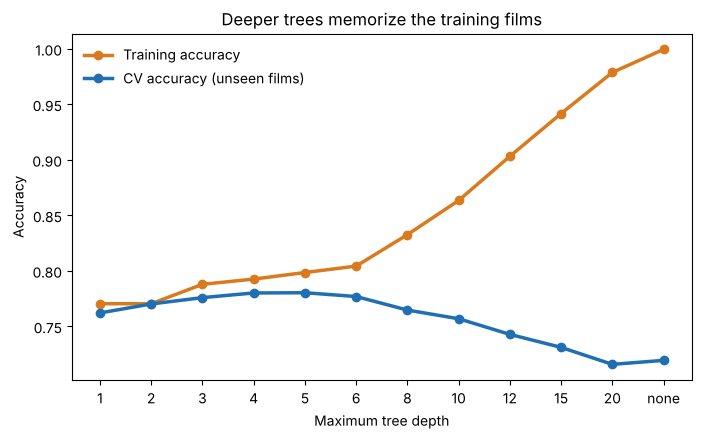

In [4]:
x = range(len(depth_sweep))
plt.figure(figsize=(8, 4.5))
plt.plot(x, depth_sweep['train_accuracy'], color='#d97a1f', linewidth=2.5, marker='o', label='Training accuracy')
plt.plot(x, depth_sweep['CV_accuracy'], color='#1f6fb2', linewidth=2.5, marker='o', label='CV accuracy (unseen films)')
plt.xticks(x, depth_sweep['max_depth'])
plt.xlabel('Maximum tree depth')
plt.ylabel('Accuracy')
plt.title('Deeper trees memorize the training films')
plt.legend(frameon=False)
plt.show()

With no depth limit, the tree grows over 700 leaves and gets almost 100% of training films right, but only about 71% of unseen films. That gap is overfitting: the deep branches describe individual films, not patterns. CV accuracy peaks at a depth of about 3 to 5.

### A shallow tree is easy to read

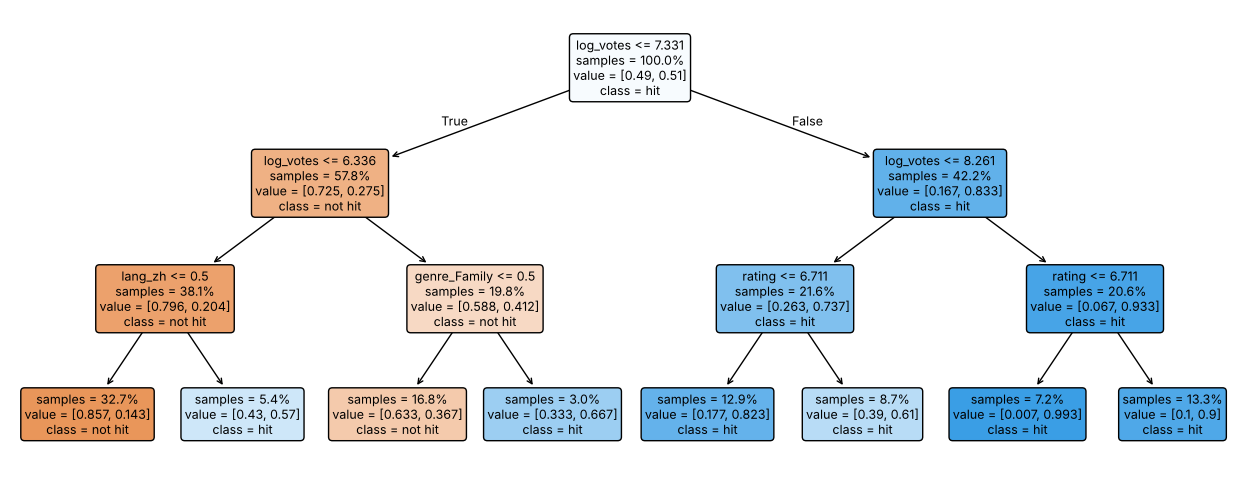

In [5]:
small_tree = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42).fit(Xc_train, yc_train)
plt.figure(figsize=(16, 6))
plot_tree(small_tree, feature_names=list(X.columns), class_names=['not hit', 'hit'],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=9)
plt.show()

The first split is on log votes (about 1,500 votes, e^7.33). Among films with fewer votes, the tree's next questions are whether the film is **Chinese** or **Family**, the same features that stood out in Weeks 2 to 4.

## 3. Tuning the tree

The lesson lists three ways to stop a tree from overfitting. I tune all three with 5 fold CV:
- **max_depth**: maximum number of questions from root to leaf
- **min_samples_leaf**: every leaf must contain at least this many films
- **min_samples_split**: a node must contain at least this many films to be split

In [6]:
tree_search = GridSearchCV(
    DecisionTreeClassifier(criterion='entropy', random_state=42),
    {'max_depth': [2, 3, 4, 5, 6, 8, 10],
     'min_samples_leaf': [1, 5, 10, 20, 50],
     'min_samples_split': [2, 10, 50]},
    cv=skf, n_jobs=-1).fit(Xc_train, yc_train)

print('Best settings:', tree_search.best_params_)
print('CV accuracy:', round(tree_search.best_score_, 4))
print('Test accuracy:', round(accuracy_score(yc_test, tree_search.predict(Xc_test)), 4))

Best settings: {'max_depth': 6, 'min_samples_leaf': 50, 'min_samples_split': 2}
CV accuracy: 0.7897
Test accuracy: 0.7763


## 4. Random forest classifier

A random forest grows many trees, each on a bootstrap sample of films, and each split may only use a random subset of features (`max_features`). The forest's prediction is the majority vote. I tune depth, leaf size, and the size of the feature subset.

In [7]:
rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    {'max_depth': [10, None],
     'min_samples_leaf': [1, 5],
     'max_features': ['sqrt', 0.5]},
    cv=skf, n_jobs=-1).fit(Xc_train, yc_train)

rf_clf = rf_search.best_estimator_
print('Best settings:', rf_search.best_params_)
print('Train accuracy:', round(accuracy_score(yc_train, rf_clf.predict(Xc_train)), 4))
print('CV accuracy:   ', round(rf_search.best_score_, 4))
print('Test accuracy: ', round(accuracy_score(yc_test, rf_clf.predict(Xc_test)), 4))

Best settings: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}
Train accuracy: 0.8988
CV accuracy:    0.8001
Test accuracy:  0.8012


### Hit classification: all models so far (same test set)

In [8]:
pd.DataFrame({
    'model': ['Logistic regression (Week 4)', 'Linear SVM, tuned (Week 5)', 'Decision tree, tuned', 'Random forest, tuned'],
    'test_accuracy': [0.7825, 0.7836,
                      round(accuracy_score(yc_test, tree_search.predict(Xc_test)), 4),
                      round(accuracy_score(yc_test, rf_clf.predict(Xc_test)), 4)]})

,model,test_accuracy
0,Logistic regression (Week 4),0.7825
1,"Linear SVM, tuned (Week 5)",0.7836
2,"Decision tree, tuned",0.7763
3,"Random forest, tuned",0.8012


## 5. Random forest regressor for log revenue

Same idea, now predicting log worldwide gross. For comparison, I also fit a single regression tree with no depth limit.

In [9]:
deep_tree = DecisionTreeRegressor(random_state=42).fit(Xr_train, yr_train)
print('Single unlimited tree: train R2', round(r2_score(yr_train, deep_tree.predict(Xr_train)), 4),
      '| test R2', round(r2_score(yr_test, deep_tree.predict(Xr_test)), 4))

rfr_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    {'max_depth': [10, None],
     'min_samples_leaf': [1, 5],
     'max_features': ['sqrt', 0.5]},
    cv=kf, scoring='r2', n_jobs=-1).fit(Xr_train, yr_train)

rf_reg = rfr_search.best_estimator_
print('Best settings:', rfr_search.best_params_)
print('Random forest: train R2', round(r2_score(yr_train, rf_reg.predict(Xr_train)), 4),
      '| CV R2', round(rfr_search.best_score_, 4),
      '| test R2', round(r2_score(yr_test, rf_reg.predict(Xr_test)), 4))

Single unlimited tree: train R2 0.9971 | test R2 0.4409


Best settings: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}


Random forest: train R2 0.8188 | CV R2 0.6899 | test R2 0.6839


### Revenue regression: all models so far (same test set)

In [10]:
pd.DataFrame({
    'model': ['Linear regression (Week 2)', 'Lasso / ridge / elastic net (Week 2)', 'Linear + squared terms (Week 1)',
              'Single unlimited tree', 'Random forest, tuned'],
    'test_R2': [0.5256, 0.527, 0.6172,
                round(r2_score(yr_test, deep_tree.predict(Xr_test)), 4),
                round(r2_score(yr_test, rf_reg.predict(Xr_test)), 4)]})

,model,test_R2
0,Linear regression (Week 2),0.5256
1,Lasso / ridge / elastic net (Week 2),0.5270
2,Linear + squared terms (Week 1),0.6172
3,Single unlimited tree,0.4409
4,"Random forest, tuned",0.6839


## 6. Feature importances

The lesson's feature importance (how much each feature reduced impurity across all splits) tends to favor continuous features, because they offer many possible split points. So I also compute **permutation importance** on the test set: shuffle one feature and measure how much test R² drops.

In [11]:
perm = permutation_importance(rf_reg, Xr_test, yr_test, n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({'impurity_importance': rf_reg.feature_importances_,
                           'R2_drop_when_shuffled': perm.importances_mean}, index=X.columns)
importance = importance.sort_values('R2_drop_when_shuffled', ascending=False)
importance.head(10).round(3)

,impurity_importance,R2_drop_when_shuffled
log_votes,0.660,1.123
year,0.117,0.144
lang_zh,0.030,0.052
rating,0.058,0.033
genre_Adventure,0.043,0.019
genre_Family,0.016,0.018
genre_Drama,0.010,0.007
genre_Action,0.010,0.004
genre_Animation,0.006,0.004
genre_Comedy,0.007,0.003


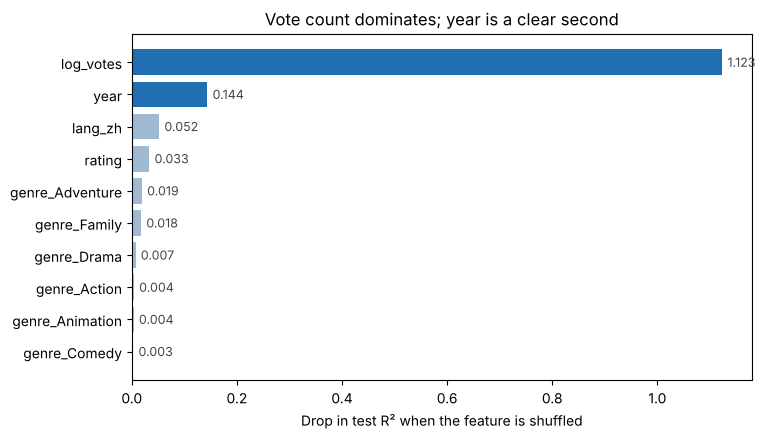

In [12]:
top = importance['R2_drop_when_shuffled'].head(10)[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top.index, top.values, color=['#1f6fb2' if i >= len(top) - 2 else '#9fb9d3' for i in range(len(top))])
for i, v in enumerate(top.values):
    plt.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=9, color='#444444')
plt.xlabel('Drop in test R² when the feature is shuffled')
plt.title('Vote count dominates; year is a clear second')
plt.show()

Vote count is by far the most important feature again (a drop above 1 means the model becomes worse than just predicting the average film). The new finding is **year in second place**. In the linear models of Weeks 2 and 3, year barely mattered (a small coefficient) because its effect is not a straight line: revenue rose until about 2016 and then crashed in 2020. A tree can split on "before 2020" vs. "2020 or later" directly.

## 7. How much can we predict before release?

Vote count and rating are only known **after** a film is out, so every model so far explains revenue more than it forecasts it. Here I refit the forest using only features a studio knows in advance: genres, language, and release year.

In [13]:
pre_release = [c for c in X.columns if c not in ('log_votes', 'rating')]

rf_pre_reg = RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_pre_reg.fit(Xr_train[pre_release], yr_train)
rf_pre_clf = RandomForestClassifier(n_estimators=300, max_features=0.5, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_pre_clf.fit(Xc_train[pre_release], yc_train)

print('Pre release random forest, test R2:      ', round(r2_score(yr_test, rf_pre_reg.predict(Xr_test[pre_release])), 4))
print('Pre release random forest, test accuracy:', round(accuracy_score(yc_test, rf_pre_clf.predict(Xc_test[pre_release])), 4))

Pre release random forest, test R2:       0.3719
Pre release random forest, test accuracy: 0.6629


# Part 2: All Three Project Datasets

My project has three datasets: the box office data used above, **MovieLens 20M** (user ratings, tags, and the tag genome), and the **4 Services Streaming** catalogs (Netflix, Prime Video, Hulu, Disney+). `OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb` joins them by cleaned title and release year and saves `combined_films.csv`.

MovieLens 20M ends in 2015, so Part 2 uses the **films released 2000 to 2015 that matched MovieLens**. To see what the extra datasets add, every model is fit twice on exactly the same films and split:
- **Box office only**: the same 32 features as Part 1
- **All three datasets**: those 32 plus 7 new ones: MovieLens rating count (log), MovieLens average rating, MovieLens tag count (log), and 0/1 flags for Netflix, Prime Video, Hulu, and Disney+

In [14]:
combo = pd.read_csv('combined_films.csv')     # same row order as the box office file
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0)]

extra = pd.DataFrame({
    'ml_log_ratings': np.log1p(sub['ml_n_ratings']),   # MovieLens: how many users rated the film
    'ml_mean_rating': sub['ml_mean_rating'],            # MovieLens: average user rating (0.5 to 5 stars)
    'ml_log_tags': np.log1p(sub['ml_n_tags']),          # MovieLens: how many tags users added
    'on_netflix': sub['on_netflix'], 'on_prime': sub['on_prime'],
    'on_hulu': sub['on_hulu'], 'on_disney': sub['on_disney'],   # streaming catalogs
}, index=sub.index)

XA = X.loc[sub.index]               # box office only
XB = pd.concat([XA, extra], axis=1)      # all three datasets
y3 = np.log(sub['$Worldwide'])                     # log worldwide gross
print('Films in Part 2:', len(sub), '| years', sub['Year'].min(), 'to', sub['Year'].max())
print('Box office features:', XA.shape[1], '| all three datasets:', XB.shape[1])

Films in Part 2: 2407 | years 2000 to 2015
Box office features: 32 | all three datasets: 39


## P2.1 Random forests with all three datasets

The tuned settings from above, refit on the 2000 to 2015 films with and without the extra features, for both tasks.

In [15]:
y3_hit = (sub['$Worldwide'] > threshold).astype(int)
tr3, te3 = train_test_split(XA.index, test_size=0.2, random_state=42)
trc3, tec3 = train_test_split(XA.index, test_size=0.2, random_state=42, stratify=y3_hit)
rows, forests3 = [], {}
for name, Z in [('Box office only', XA), ('All three datasets', XB)]:
    reg = RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Z.loc[tr3], y3[tr3])
    clf = RandomForestClassifier(n_estimators=300, max_depth=10, max_features=0.5, random_state=42, n_jobs=-1).fit(Z.loc[trc3], y3_hit[trc3])
    forests3[name] = reg
    rows.append({'features': name, 'n_features': Z.shape[1],
                 'test_R2 (revenue)': round(r2_score(y3[te3], reg.predict(Z.loc[te3])), 4),
                 'test_accuracy (hit)': round(accuracy_score(y3_hit[tec3], clf.predict(Z.loc[tec3])), 4)})
pd.DataFrame(rows)

,features,n_features,test_R2 (revenue),test_accuracy (hit)
0,Box office only,32,0.7122,0.8029
1,All three datasets,39,0.7307,0.8091


In [16]:
perm3 = permutation_importance(forests3['All three datasets'], XB.loc[te3], y3[te3], n_repeats=5, random_state=42, n_jobs=-1)
pd.Series(perm3.importances_mean, index=XB.columns).sort_values(ascending=False).head(10).round(3).rename('R2_drop_when_shuffled')

log_votes          0.967
year               0.067
ml_log_ratings     0.043
ml_mean_rating     0.037
genre_Adventure    0.020
ml_log_tags        0.020
rating             0.015
genre_Family       0.013
genre_Animation    0.004
genre_Drama        0.004
Name: R2_drop_when_shuffled, dtype: float64

## P2.2 Random forest vs. lasso on the tag genome

Week 2 found that lasso does very well with the 1,128 genome tags. Can a random forest do better with the same features?

In [17]:
# MovieLens tag genome: 1,128 relevance scores (0 to 1) per film, saved by the data prep notebook
genome = pd.read_csv('genome_features.csv', index_col=0)
has_genome = sub['ml_movieId'].astype(int).isin(genome.index)
gsub = sub[has_genome]
G = genome.loc[gsub['ml_movieId'].astype(int)].set_index(gsub.index)
print('Films with tag genome scores:', len(gsub), '| genome tags:', G.shape[1])

Films with tag genome scores: 2179 | genome tags: 1128


In [18]:
XG = pd.concat([XB.loc[gsub.index], G], axis=1)
y_g = y3[gsub.index]
trg, teg = train_test_split(XG.index, test_size=0.2, random_state=42)
rf_g = RandomForestRegressor(n_estimators=300, max_features=0.3, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(XG.loc[trg], y_g[trg])
rf_b = RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(XB.loc[trg], y_g[trg])
print('Random forest, all three datasets without genome: test R2', round(r2_score(y_g[teg], rf_b.predict(XB.loc[teg])), 4))
print('Random forest, all three datasets + genome:       test R2', round(r2_score(y_g[teg], rf_g.predict(XG.loc[teg])), 4))

Random forest, all three datasets without genome: test R2 0.7341
Random forest, all three datasets + genome:       test R2 0.7452


## 8. Conclusions

**Random forests are the best models so far, for both tasks.**
- **Hit classification:** the tuned forest reaches **80.1%** test accuracy (CV 80.0%), about 2 points better than logistic regression (78.3%) and the linear SVM (78.4%). A single tuned tree (77.6%) did slightly worse than those linear models.
- **Revenue regression:** the forest reaches a test R² of **0.684**, compared with 0.617 for the polynomial model of Week 1 and 0.526 for the linear models of Week 2. That is the largest improvement in the whole module.

**Single trees overfit badly; forests fix most of it.** An unlimited classification tree grew 727 leaves and scored 99.95% on training films but only 72% in CV. An unlimited regression tree had a training R² of 0.997 and a test R² of only 0.441, worse than plain linear regression. Limiting depth and leaf size helps a single tree, but averaging 300 decorrelated trees helps far more.

**Hyperparameters chosen by CV, and what they mean here:**
- `max_depth`: how many questions a tree may ask about a film. CV preferred about 4 to 6 for a single tree, and deeper trees inside a forest because averaging cancels their noise.
- `min_samples_leaf`: the smallest group of films a prediction can be based on. The tuned single tree wanted 50, so no rule is based on a handful of films. The regression forest wanted 5.
- `max_features = 0.5`: each split may only look at half of the 32 features. Because vote count dominates, this forces many splits to use other features (year, language, genre), which makes the trees different from each other.

**The forest's train scores are higher than its test scores** (0.899 vs. 0.801 accuracy, 0.819 vs. 0.684 R²). This is normal for random forests, since each tree has seen most training films. What matters is that CV and test results agree closely, so the reported performance is honest.

**What drives revenue:** vote count first, then **year**, then Chinese language, then rating. Year ranks second here even though it barely mattered in the linear models, because its effect is not a straight line (the 2020 collapse). Trees capture that kind of break naturally.

**The most important result for my capstone:** using only pre release features (genres, language, year), the forest still reaches a test R² of **0.37** and 66% accuracy. Vote count makes the models look strong, but it is measured after release. A studio deciding *before* release would get much weaker predictions, so Milestone Two should focus on pre release features (and possibly MovieLens and streaming data) to close that gap.

**Part 2 (all three datasets).** On the 2000 to 2015 films, the MovieLens and streaming features raise the forest's test R² and accuracy modestly. Permutation importance ranks TMDB votes first, then year, then the two MovieLens audience measures; none of the streaming flags matter much. Adding the 1,128 genome tags helps the forest only slightly, and it still falls short of the Week 2 lasso on the same films. With many sparse, mostly weak features, a forest that samples a fraction of features per split often misses the few useful tags, while lasso can weigh all of them at once. Trees are not automatically the best choice.

### Think About It

- **Why is there a minus sign in the definition of entropy?** Each probability p is between 0 and 1, so log(p) is zero or negative. The minus sign makes entropy zero or positive, so that "more missing information" is a bigger number.
- **With 1,024 samples, how many nodes are needed so that each leaf has one sample?** There must be 1,024 leaves. In a binary tree, every split adds exactly one leaf, so there are 1,023 decision (internal) nodes, for **2,047 nodes** in total.
- **How many decisions from the root to a single leaf?** If every split divides the samples in half, **10** decisions, since 2¹⁰ = 1,024. An unbalanced tree would need more for some leaves (my unlimited tree reached a depth of 35).
- **Why does a random forest randomize features?** Otherwise every tree would split on log votes first and make nearly the same mistakes, so averaging them would not help. Restricting each split to a random subset makes the trees different from each other.
- **Why does a random forest combine the judgments of many trees?** Each deep tree overfits in its own way. When their predictions are averaged (regression) or voted on (classification), those individual errors largely cancel out, while the real patterns they share remain. That is why the forest beat every single tree here.